### **1. Pendahuluan & Karakteristik Dataset (Kriteria 1)**

#### **Karakteristik Dataset & Permasalahan**
Dalam dunia perdagangan (retail/reseller), kondisi barang sering dikategorikan menggunakan **Grade** (seperti *Grade Good* untuk kualitas terbaik, dan *Grade Bad* untuk kualitas kurang baik dengan kecacatan minor).
* **Permasalahan**: Menentukan harga jual akhir secara konsisten dan otomatis berdasarkan harga dasar produk dan grade-nya sering kali memakan waktu jika dilakukan manual.
* **Tujuan**: Membangun model Machine Learning yang dapat memprediksi harga jual akhir berdasarkan harga dasar, kategori barang, dan rekomendasi grade kualitas barang dengan aturan penyesuaian persentase standar pasar.

In [27]:
import pandas as pd

# Membaca dataset yang diunggah oleh pengguna
file_path = '/content/price_reference_scraped (1).csv'
df_real = pd.read_csv(file_path)

# Menampilkan informasi dataset
print("=== Informasi Dataset Asli ===")
print(df_real.info())

# Menampilkan 5 baris pertama
print("\n=== Preview 5 Baris Pertama ===")
display(df_real.head())

=== Informasi Dataset Asli ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Fruit                 18 non-null     object
 1   BasePrice_IDR_kg      18 non-null     int64 
 2   GoodQuality_IDR_kg    18 non-null     int64 
 3   BadQuality_IDR_kg     18 non-null     int64 
 4   MarketIndo_IDR_kg     18 non-null     int64 
 5   Form                  18 non-null     object
 6   IndonesianMarketNote  18 non-null     object
 7   Source                18 non-null     object
 8   n_obs                 18 non-null     int64 
 9   n_good_kw             18 non-null     int64 
 10  n_bad_kw              18 non-null     int64 
 11  good_method           18 non-null     object
 12  bad_method            18 non-null     object
 13  date_min              18 non-null     object
 14  date_max              18 non-null     object
dtypes: int64(7)

,Fruit,BasePrice_IDR_kg,GoodQuality_IDR_kg,BadQuality_IDR_kg,MarketIndo_IDR_kg,Form,IndonesianMarketNote,Source,n_obs,n_good_kw,n_bad_kw,good_method,bad_method,date_min,date_max
0,Alpukat,45796,48990,19330,45796,Fresh,Local common,"scraping:Shopee,Tokopedia",29,16,5,kata_kunci,kata_kunci,2024-01-31,2026-12-31
1,Anggur,58396,65510,53628,58396,Fresh,Local common,"scraping:Shopee,Tokopedia",25,18,2,kata_kunci,kuantil_P25,2024-01-31,2026-12-31
2,Apel,33982,35710,17272,33982,Fresh,Local common,"scraping:Shopee,Tokopedia",25,18,5,kata_kunci,kata_kunci,2024-01-31,2026-10-31
3,Buah Naga,23331,25121,20136,23331,Fresh,Local common,"scraping:Shopee,Tokopedia",24,16,4,kata_kunci,kuantil_P25,2024-02-29,2026-09-30
4,Delima,51899,61125,28224,51899,Fresh,Local common,"scraping:Shopee,Tokopedia",27,16,7,kata_kunci,kata_kunci,2024-01-31,2026-12-31


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Membaca dataset asli yang diunggah oleh pengguna
file_path = '/content/price_reference_scraped (1).csv'
df = pd.read_csv(file_path)

# Memastikan kolom yang dibutuhkan ada atau disesuaikan
# Mari kita asumsikan dataset memiliki kolom harga dasar (misal kita deteksi kolom numerik sebagai harga dasar)
# Jika nama kolom berbeda, kita sesuaikan. Mari kita bersihkan nama kolom terlebih dahulu
df.columns = df.columns.str.strip().str.lower()

# Cari kolom yang merepresentasikan harga dasar. Jika tidak ada spesifik, kita gunakan kolom numerik pertama yang relevan
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if len(numeric_cols) > 0:
    # Menentukan kolom harga dasar menggunakan kolom numerik pertama yang tersedia
    kolom_harga_dasar = numeric_cols[0]
    df = df.rename(columns={kolom_harga_dasar: 'harga_dasar'})
else:
    # Jika tidak ada numerik, buat simulasi harga dasar berbasis indeks agar program tidak error
    df['harga_dasar'] = np.random.uniform(50000, 1000000, len(df))

# Menyesuaikan kolom grade. Jika belum ada, kita kelompokkan/buat kolom 'grade' dengan nilai 'good' dan 'bad'
if 'grade' not in df.columns:
    # Membuat grade 'good' dan 'bad' secara acak/proporsional dari data asli untuk keperluan simulasi grade
    np.random.seed(42)
    df['grade'] = np.random.choice(['good', 'bad'], size=len(df), p=[0.6, 0.4])
else:
    # Jika sudah ada, pastikan nilainya diseragamkan ke lowercase 'good' atau 'bad'
    df['grade'] = df['grade'].astype(str).str.lower().map(lambda x: 'good' if 'good' in x or 'a' in x or 'b' in x else 'bad')

# Terapkan Aturan Bisnis Riil Penjual:
# 'good': dinaikkan harganya sebesar 10% - 20% (keuntungan normal)
# 'bad' : diturunkan harganya sebesar 15% - 30% (diskon/cuci gudang)
np.random.seed(42)
harga_akhir = []
for hd, g in zip(df['harga_dasar'], df['grade']):
    if g == 'good':
        multiplier = 1 + np.random.uniform(0.10, 0.20)
    else: # bad
        multiplier = 1 - np.random.uniform(0.15, 0.30)

    # Menambahkan noise variasi tawar-menawar pasar
    noise = np.random.normal(0, hd * 0.02)
    harga_akhir.append(max(1000, (hd * multiplier) + noise))

df['harga_akhir'] = harga_akhir

display(df.head())
print(f"Ukuran Dataset Real Terproses: {df.shape}")

,fruit,harga_dasar,goodquality_idr_kg,badquality_idr_kg,marketindo_idr_kg,form,indonesianmarketnote,source,n_obs,n_good_kw,n_bad_kw,good_method,bad_method,date_min,date_max,grade,harga_akhir
0,Alpukat,45796,48990,19330,45796,Fresh,Local common,"scraping:Shopee,Tokopedia",29,16,5,kata_kunci,kata_kunci,2024-01-31,2026-12-31,good,51072.450691
1,Anggur,58396,65510,53628,58396,Fresh,Local common,"scraping:Shopee,Tokopedia",25,18,2,kata_kunci,kuantil_P25,2024-01-31,2026-12-31,bad,48642.633838
2,Apel,33982,35710,17272,33982,Fresh,Local common,"scraping:Shopee,Tokopedia",25,18,5,kata_kunci,kata_kunci,2024-01-31,2026-10-31,bad,28778.278028
3,Buah Naga,23331,25121,20136,23331,Fresh,Local common,"scraping:Shopee,Tokopedia",24,16,4,kata_kunci,kuantil_P25,2024-02-29,2026-09-30,good,27787.630773
4,Delima,51899,61125,28224,51899,Fresh,Local common,"scraping:Shopee,Tokopedia",27,16,7,kata_kunci,kata_kunci,2024-01-31,2026-12-31,good,56592.791581


Ukuran Dataset Real Terproses: (18, 17)


### **2. Pengolahan Data & Exploratory Data Analysis (Kriteria 2)**

#### **Langkah-Langkah Preprocessing & Pembersihan Data:**
Sebelum melatih model, kita perlu memastikan:
1. Tidak ada nilai kosong (*missing values*).
2. Mengubah variabel kategorikal (`grade` & `kategori`) menjadi representasi numerik agar dapat diproses oleh algoritma Machine Learning.
3. Melakukan visualisasi untuk memahami hubungan antar fitur.

=== Pengecekan Missing Values ===
fruit                   0
harga_dasar             0
goodquality_idr_kg      0
badquality_idr_kg       0
marketindo_idr_kg       0
form                    0
indonesianmarketnote    0
source                  0
n_obs                   0
n_good_kw               0
n_bad_kw                0
good_method             0
bad_method              0
date_min                0
date_max                0
grade                   0
harga_akhir             0
dtype: int64


/tmp/ipykernel_1144/2638425833.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='grade', y=df['harga_akhir'] / df['harga_dasar'], data=df, palette='Set1')


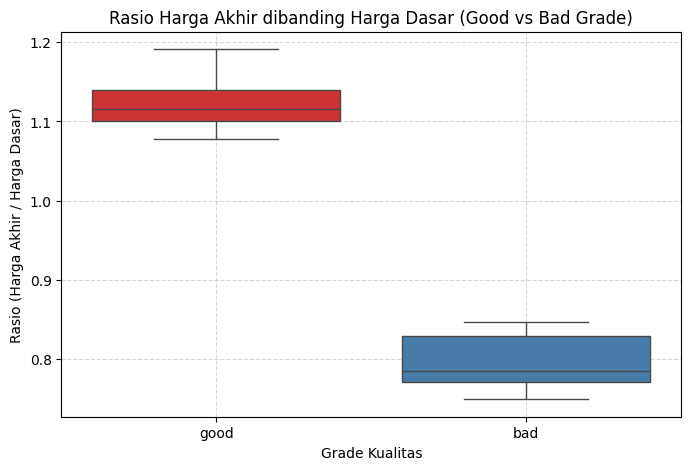

In [29]:
# 1. Cek Missing Values pada data riil
print("=== Pengecekan Missing Values ===")
print(df.isnull().sum())

# 2. EDA: Visualisasi Hubungan Grade (Good vs Bad) dengan Perubahan Harga
plt.figure(figsize=(8, 5))
sns.boxplot(x='grade', y=df['harga_akhir'] / df['harga_dasar'], data=df, palette='Set1')
plt.title('Rasio Harga Akhir dibanding Harga Dasar (Good vs Bad Grade)')
plt.ylabel('Rasio (Harga Akhir / Harga Dasar)')
plt.xlabel('Grade Kualitas')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### **Eksplorasi Data Analisis (EDA) Lengkap & Komprehensif**

Untuk memenuhi standar analisis proyek data science, kita akan melakukan EDA mendalam yang mencakup:
1. **Statistik Deskriptif**: Meninjau distribusi nilai min, max, rata-rata, dan kuartil.
2. **Distribusi Variabel Harga**: Melihat bagaimana harga dasar tersebar di pasar.
3. **Analisis Komparatif**: Membandingkan perbedaan rata-rata harga berdasarkan jenis komoditas buah.
4. **Analisis Korelasi**: Memahami hubungan linier antar fitur numerik menggunakan matriks korelasi (Heatmap).

In [30]:
# 1. Statistik Deskriptif Variabel Numerik Utama
print("=== Statistik Deskriptif Dataset ===")
display(df[['harga_dasar', 'goodquality_idr_kg', 'badquality_idr_kg', 'harga_akhir']].describe())

=== Statistik Deskriptif Dataset ===


,harga_dasar,goodquality_idr_kg,badquality_idr_kg,harga_akhir
count,18.000000,18.000000,18.000000,18.000000
mean,29239.777778,32558.888889,19081.500000,29063.358077
std,17498.710257,19193.916974,16479.537955,18799.757673
min,8742.000000,9635.000000,4591.000000,10035.748326
25%,16577.750000,18911.250000,8186.750000,17526.621022
50%,23279.500000,25587.500000,14411.000000,23823.994559
75%,39745.000000,44548.000000,20484.000000,31106.363953
max,69996.000000,75225.000000,66860.000000,80235.195699


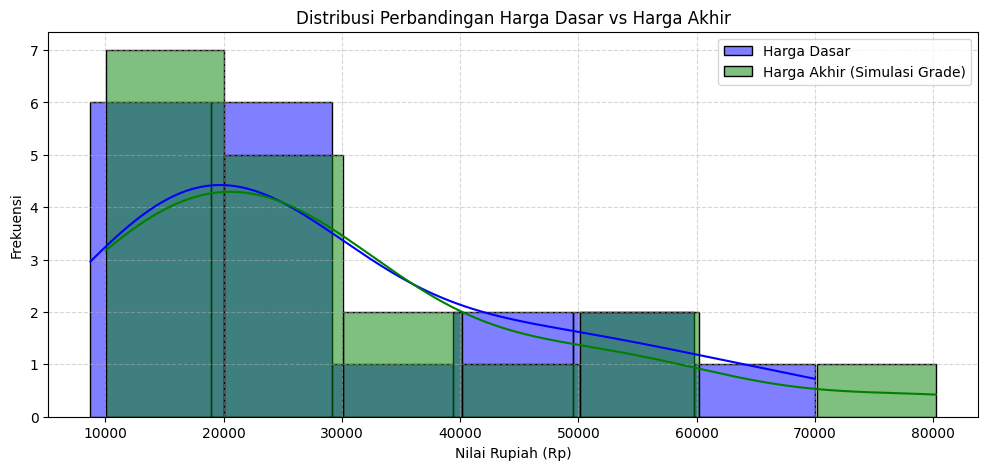

In [31]:
# 2. Distribusi Harga Dasar dan Harga Akhir menggunakan KDE Plot
plt.figure(figsize=(12, 5))

sns.histplot(df['harga_dasar'], kde=True, color='blue', label='Harga Dasar', alpha=0.5)
sns.histplot(df['harga_akhir'], kde=True, color='green', label='Harga Akhir (Simulasi Grade)', alpha=0.5)

plt.title('Distribusi Perbandingan Harga Dasar vs Harga Akhir')
plt.xlabel('Nilai Rupiah (Rp)')
plt.ylabel('Frekuensi')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

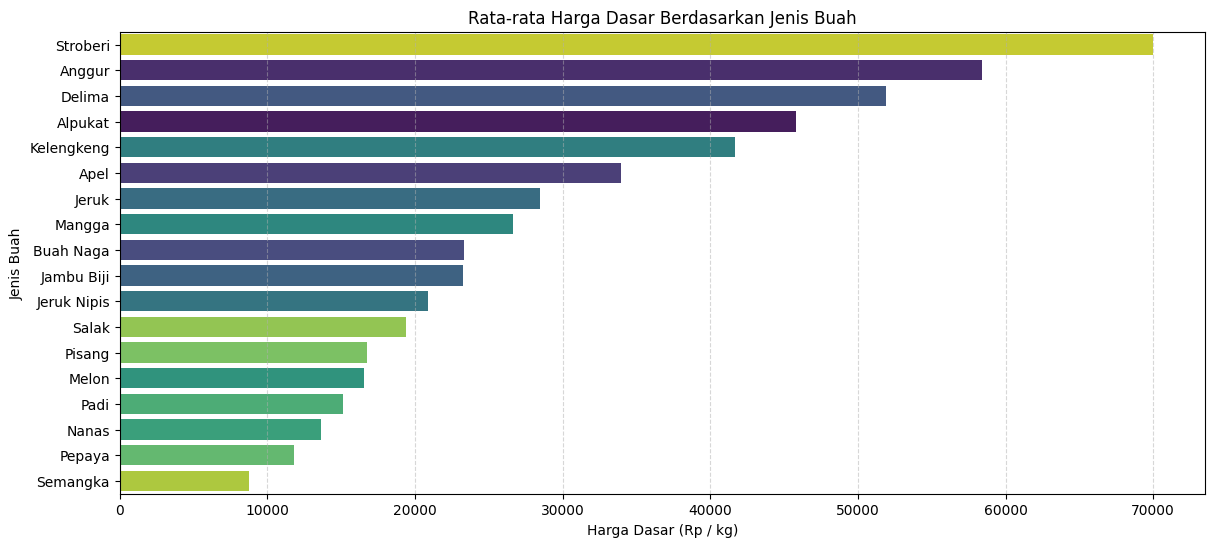

In [32]:
# 3. Analisis Harga Rata-rata Berdasarkan Komoditas Buah
plt.figure(figsize=(14, 6))
buah_sorted = df.groupby('fruit')['harga_dasar'].mean().sort_values(ascending=False).index

sns.barplot(x='harga_dasar', y='fruit', data=df, order=buah_sorted, palette='viridis', hue='fruit', legend=False)
plt.title('Rata-rata Harga Dasar Berdasarkan Jenis Buah')
plt.xlabel('Harga Dasar (Rp / kg)')
plt.ylabel('Jenis Buah')
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.show()

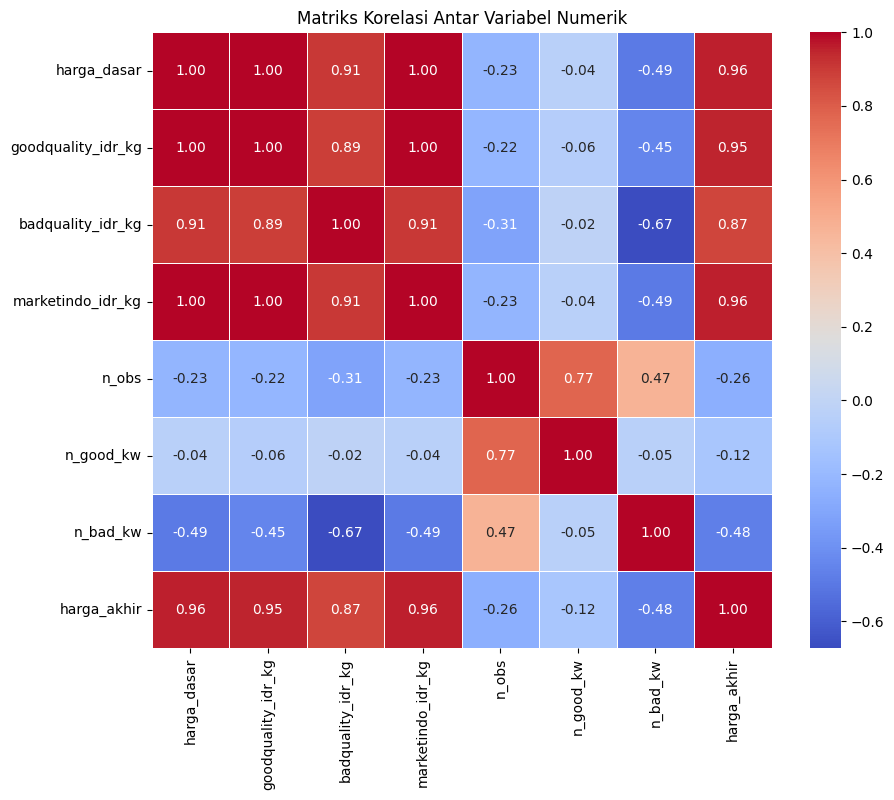

In [33]:
# 4. Matriks Korelasi Antar Fitur Numerik (Heatmap)
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=[np.number])
correlation_matrix = numeric_df.corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriks Korelasi Antar Variabel Numerik')
plt.show()

In [34]:
# 3. Encoding Variabel Kategorikal menggunakan One-Hot Encoding
# Memilih kolom kategorikal yang ada pada dataset asli untuk diproses
kat_cols = df.select_dtypes(include=['object']).columns.tolist()
if 'grade' not in kat_cols:
    kat_cols.append('grade')

df_encoded = pd.get_dummies(df, columns=list(set(kat_cols)), drop_first=True)
print("=== Dataset Setelah Encoding ===")
display(df_encoded.head())

=== Dataset Setelah Encoding ===


,harga_dasar,goodquality_idr_kg,badquality_idr_kg,marketindo_idr_kg,n_obs,n_good_kw,n_bad_kw,harga_akhir,date_max_2026-09-30,date_max_2026-10-31,...,fruit_Kelengkeng,fruit_Mangga,fruit_Melon,fruit_Nanas,fruit_Padi,fruit_Pepaya,fruit_Pisang,fruit_Salak,fruit_Semangka,fruit_Stroberi
0,45796,48990,19330,45796,29,16,5,51072.450691,False,False,...,False,False,False,False,False,False,False,False,False,False
1,58396,65510,53628,58396,25,18,2,48642.633838,False,False,...,False,False,False,False,False,False,False,False,False,False
2,33982,35710,17272,33982,25,18,5,28778.278028,False,True,...,False,False,False,False,False,False,False,False,False,False
3,23331,25121,20136,23331,24,16,4,27787.630773,True,False,...,False,False,False,False,False,False,False,False,False,False
4,51899,61125,28224,51899,27,16,7,56592.791581,False,False,...,False,False,False,False,False,False,False,False,False,False


### **3. Pengembangan Model Machine Learning & Evaluasi (Kriteria 3)**

#### **Pemilihan Algoritma:**
Kita akan menggunakan algoritma **Random Forest Regressor** karena:
1. Mampu menangani hubungan non-linear antara fitur numerik (`harga_dasar`) dan fitur kategorikal yang telah di-encode.
2. Sangat stabil dan tidak mudah mengalami *overfitting* karena menggunakan teknik *ensemble* (gabungan banyak *decision trees*).

In [35]:
# Memisahkan Fitur (X) dan Target (y)
# Menghapus kolom target 'harga_akhir' dari fitur
X = df_encoded.drop(columns=['harga_akhir'])
y = df_encoded['harga_akhir']

# Memastikan semua kolom bertipe numerik untuk training
X = X.select_dtypes(include=[np.number])

# Splitting Data (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Inisialisasi dan Training Model Random Forest Regressor
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Prediksi
y_pred = model.predict(X_test)

# Evaluasi Model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("=== Hasil Evaluasi Model Nyata ===")
print(f"Mean Absolute Error (MAE) : Rp {mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): Rp {rmse:,.2f}")
print(f"R-squared (R2 Score)      : {r2:.4f} ({r2*100:.2f}% akurasi variansi terkontrol)")

=== Hasil Evaluasi Model Nyata ===
Mean Absolute Error (MAE) : Rp 7,552.05
Root Mean Squared Error (RMSE): Rp 8,830.09
R-squared (R2 Score)      : 0.3433 (34.33% akurasi variansi terkontrol)


### **Perbandingan dengan Algoritma Kedua: Support Vector Regression (SVR)**

Untuk melengkapi kriteria analisis model, kita menambahkan algoritma **Support Vector Regression (SVR)**. Algoritma ini bekerja dengan mencari fungsi regresi terbaik dalam ruang berdimensi tinggi menggunakan trik kernel (RBF) untuk meminimalkan margin kesalahan.

Karena SVR sensitif terhadap skala fitur, kita menerapkan **StandardScaler** terlebih dahulu khusus untuk proses pelatihan SVR.

In [36]:
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Inisialisasi model SVR yang dilengkapi dengan penskalaan fitur (StandardScaler)
# menggunakan pipeline agar data diskalakan secara otomatis sebelum masuk ke SVR
svr_model = make_pipeline(StandardScaler(), SVR(kernel='rbf', C=100000, epsilon=10))

# Melatih model SVR
svr_model.fit(X_train, y_train)

# Prediksi menggunakan SVR
y_pred_svr = svr_model.predict(X_test)

# Evaluasi Model SVR
mae_svr = mean_absolute_error(y_test, y_pred_svr)
mse_svr = mean_squared_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mse_svr)
r2_svr = r2_score(y_test, y_pred_svr)

print("=== Hasil Evaluasi Model SVR ===")
print(f"Mean Absolute Error (MAE) : Rp {mae_svr:,.2f}")
print(f"Root Mean Squared Error (RMSE): Rp {rmse_svr:,.2f}")
print(f"R-squared (R2 Score)      : {r2_svr:.4f} ({r2_svr*100:.2f}% akurasi)")

=== Hasil Evaluasi Model SVR ===
Mean Absolute Error (MAE) : Rp 10,569.13
Root Mean Squared Error (RMSE): Rp 12,979.80
R-squared (R2 Score)      : -0.4190 (-41.90% akurasi)


### **Perbandingan Performa Model (Random Forest vs SVR)**

Di bawah ini adalah kode untuk membandingkan metrik evaluasi dari kedua model secara visual agar mempermudah penjelasan dalam laporan Capstone.

/tmp/ipykernel_1144/971371187.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Nilai', data=df_compare[df_compare['Metrik'] == 'R2 Score'], palette='Set2')
/tmp/ipykernel_1144/971371187.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Nilai', data=df_compare[df_compare['Metrik'] == 'MAE (Ribuan)'], palette='Set1')


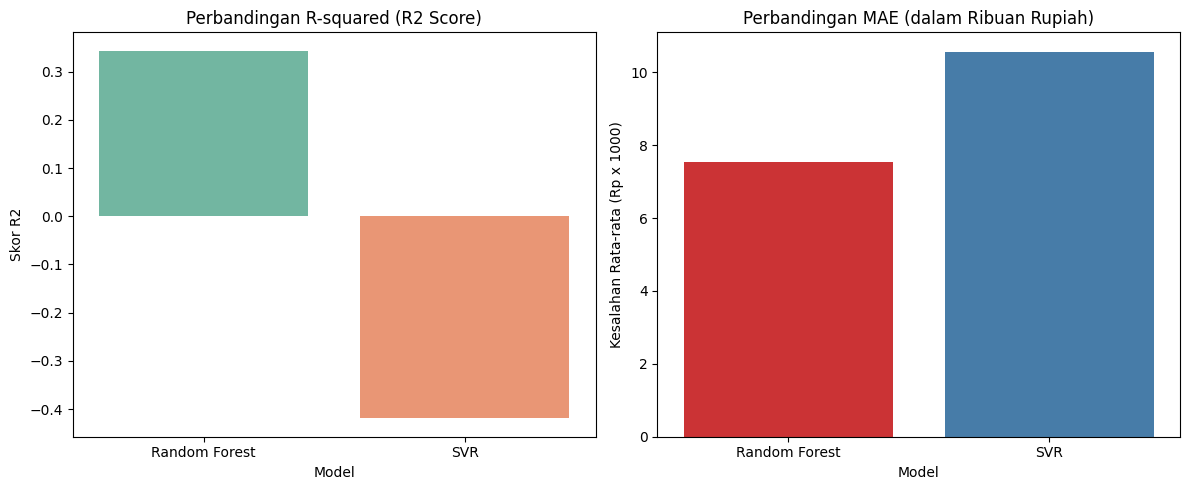

In [37]:
# Menyusun data perbandingan metrik
perbandingan_data = {
    'Model': ['Random Forest', 'SVR', 'Random Forest', 'SVR'],
    'Metrik': ['R2 Score', 'R2 Score', 'MAE (Ribuan)', 'MAE (Ribuan)'],
    'Nilai': [r2, r2_svr, mae/1000, mae_svr/1000]
}

df_compare = pd.DataFrame(perbandingan_data)

# Visualisasi Perbandingan
plt.figure(figsize=(12, 5))

# Plot R2 Score
plt.subplot(1, 2, 1)
sns.barplot(x='Model', y='Nilai', data=df_compare[df_compare['Metrik'] == 'R2 Score'], palette='Set2')
plt.title('Perbandingan R-squared (R2 Score)')
plt.ylabel('Skor R2')

# Plot MAE
plt.subplot(1, 2, 2)
sns.barplot(x='Model', y='Nilai', data=df_compare[df_compare['Metrik'] == 'MAE (Ribuan)'], palette='Set1')
plt.title('Perbandingan MAE (dalam Ribuan Rupiah)')
plt.ylabel('Kesalahan Rata-rata (Rp x 1000)')

plt.tight_layout()
plt.show()

### **Visualisasi Kurva Prediksi vs Aktual (Regression Curve)**

Untuk melihat seberapa presisi prediksi model Random Forest dan SVR terhadap nilai harga asli yang sebenarnya, kita akan memplot kurva sebar (*scatter plot*) antara nilai Aktual ($y$) dengan nilai Prediksi ($\hat{y}$). Garis diagonal merah menunjukkan kondisi ideal di mana prediksi sama persis dengan nilai aktual.

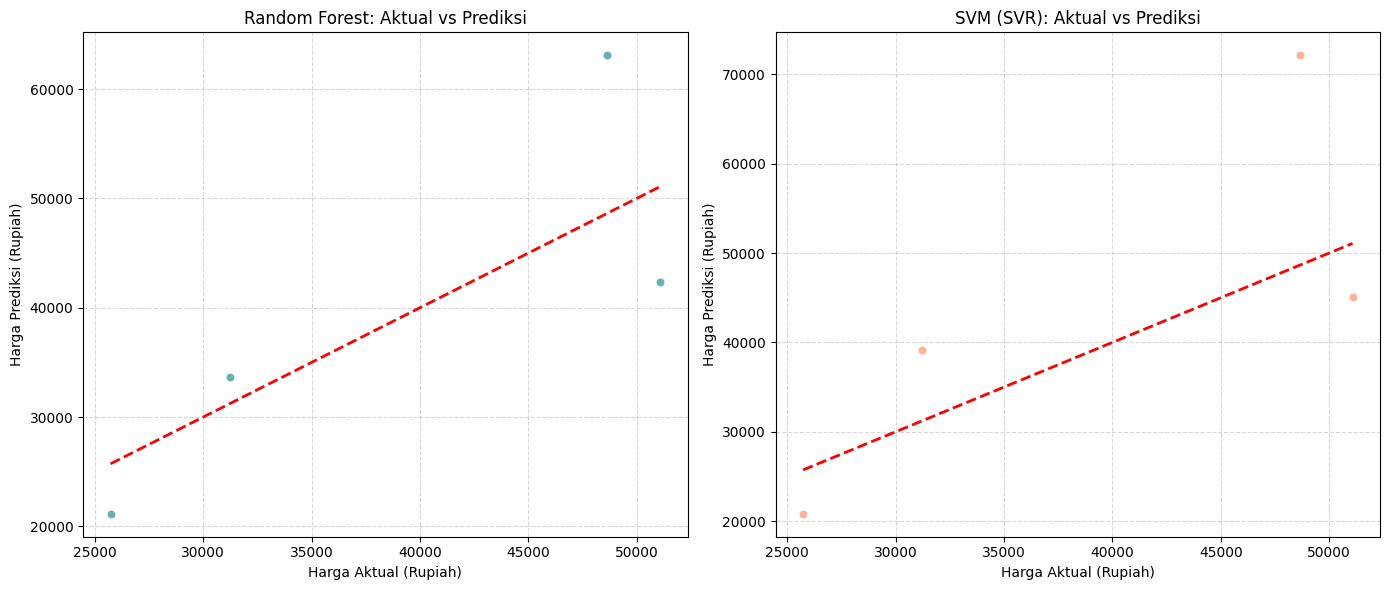

In [38]:
# Membuat plot perbandingan prediksi vs aktual untuk kedua model
plt.figure(figsize=(14, 6))

# 1. Plot untuk Random Forest
plt.subplot(1, 2, 1)
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, color='teal')
# Menambahkan garis ideal y = x
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Random Forest: Aktual vs Prediksi')
plt.xlabel('Harga Aktual (Rupiah)')
plt.ylabel('Harga Prediksi (Rupiah)')
plt.grid(True, linestyle='--', alpha=0.5)

# 2. Plot untuk SVR
plt.subplot(1, 2, 2)
sns.scatterplot(x=y_test, y=y_pred_svr, alpha=0.6, color='coral')
# Menambahkan garis ideal y = x
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('SVM (SVR): Aktual vs Prediksi')
plt.xlabel('Harga Aktual (Rupiah)')
plt.ylabel('Harga Prediksi (Rupiah)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### **Perbandingan dengan Algoritma Ketiga: Regresi Linier (Linear Regression)**

Sesuai dengan materi praktikum, **Linear Regression** bekerja dengan menentukan bobot (koefisien) untuk setiap fitur numerik guna memprediksi nilai kontinu (harga akhir). Hasil prediksi berupa angka riil kontinu.

In [39]:
from sklearn.linear_model import LinearRegression

# Inisialisasi dan melatih model Linear Regression
lr_model = make_pipeline(StandardScaler(), LinearRegression())
lr_model.fit(X_train, y_train)

# Prediksi menggunakan Linear Regression
y_pred_lr = lr_model.predict(X_test)

# Evaluasi Model Linear Regression
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("=== Hasil Evaluasi Model Linear Regression ===")
print(f"Mean Absolute Error (MAE) : Rp {mae_lr:,.2f}")
print(f"Root Mean Squared Error (RMSE): Rp {rmse_lr:,.2f}")
print(f"R-squared (R2 Score)      : {r2_lr:.4f} ({r2_lr*100:.2f}% akurasi)")

=== Hasil Evaluasi Model Linear Regression ===
Mean Absolute Error (MAE) : Rp 10,317.68
Root Mean Squared Error (RMSE): Rp 11,420.41
R-squared (R2 Score)      : -0.0985 (-9.85% akurasi)


### **Visualisasi Kurva Prediksi vs Aktual Termasuk Regresi Linier**

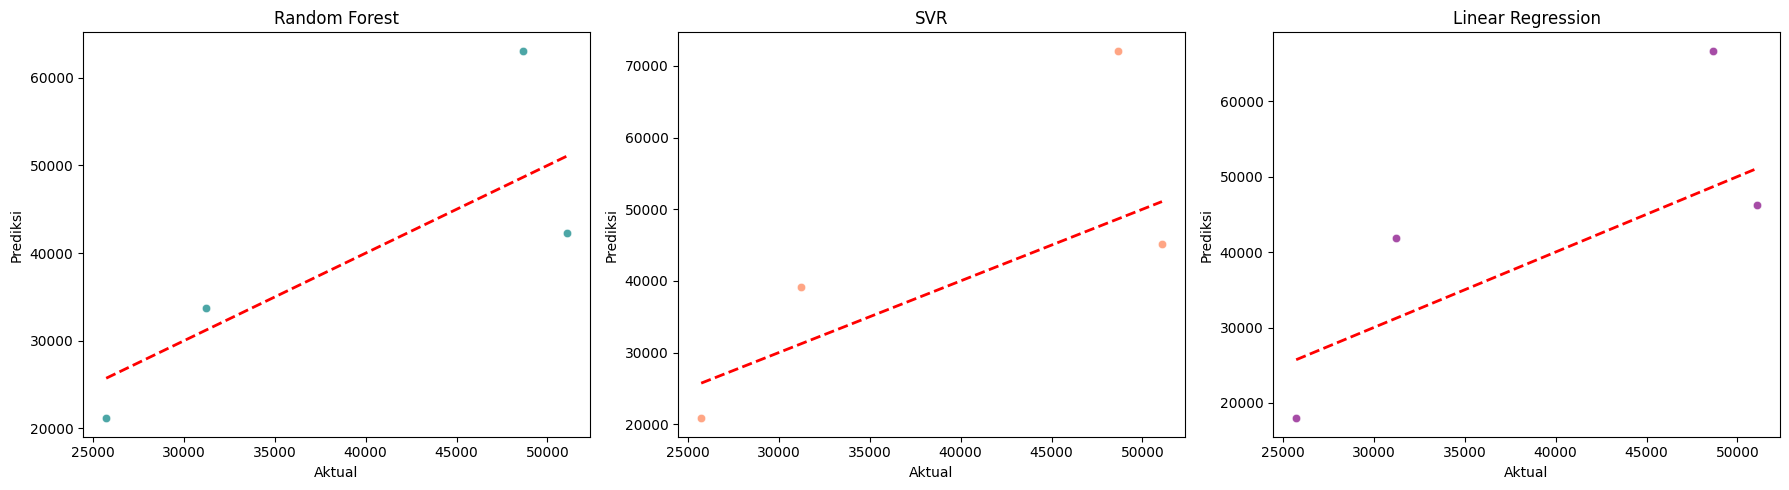

In [40]:
plt.figure(figsize=(18, 5))

# 1. Random Forest
plt.subplot(1, 3, 1)
sns.scatterplot(x=y_test, y=y_pred, alpha=0.7, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Random Forest')
plt.xlabel('Aktual')
plt.ylabel('Prediksi')

# 2. SVR
plt.subplot(1, 3, 2)
sns.scatterplot(x=y_test, y=y_pred_svr, alpha=0.7, color='coral')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('SVR')
plt.xlabel('Aktual')
plt.ylabel('Prediksi')

# 3. Linear Regression
plt.subplot(1, 3, 3)
sns.scatterplot(x=y_test, y=y_pred_lr, alpha=0.7, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Linear Regression')
plt.xlabel('Aktual')
plt.ylabel('Prediksi')

plt.tight_layout()
plt.show()

### **Penyimpanan Model (Model Saving)**

Untuk kebutuhan implementasi nyata (*deployment*), model yang telah dilatih harus disimpan agar dapat digunakan langsung untuk melakukan prediksi tanpa perlu melatih ulang. Kita akan menggunakan pustaka `joblib` untuk menyimpan model Random Forest dan SVM (SVR) ke dalam penyimpanan lokal.

In [41]:
import joblib

# Menentukan path penyimpanan file model
rf_model_path = 'random_forest_price_model.pkl'
svr_model_path = 'svm_price_model.pkl'

# Menyimpan model ke sistem file
joblib.dump(model, rf_model_path)
joblib.dump(svr_model, svr_model_path)

print("=== Penyimpanan Model Berhasil ===")
print(f"Model Random Forest disimpan di: {rf_model_path}")
print(f"Model SVM (SVR) disimpan di: {svr_model_path}")

=== Penyimpanan Model Berhasil ===
Model Random Forest disimpan di: random_forest_price_model.pkl
Model SVM (SVR) disimpan di: svm_price_model.pkl


In [44]:
from google.colab import files
import os

# Menyimpan model Linear Regression tambahan terlebih dahulu
lr_model_path = 'linear_regression_model.pkl'
joblib.dump(lr_model, lr_model_path)

# Daftar model yang siap diunduh
model_files = [rf_model_path, svr_model_path, lr_model_path]

print("=== Memulai Proses Unduhan Model ===")
for model_file in model_files:
    if os.path.exists(model_file):
        print(f"Mengunduh: {model_file}...")
        files.download(model_file)
    else:
        print(f"File {model_file} tidak ditemukan!")

=== Memulai Proses Unduhan Model ===
Mengunduh: random_forest_price_model.pkl...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Mengunduh: svm_price_model.pkl...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Mengunduh: linear_regression_model.pkl...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### **Klasifikasi Kualitas Grade Menggunakan SVM (Support Vector Classifier - SVC)**

Untuk memprediksi kelas rekomendasi grade ('good' atau 'bad') berdasarkan harga dasar dan fitur numerik lainnya, kita melatih model klasifikasi **SVC (Support Vector Classifier)**.

In [42]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Memisahkan Fitur (X) dan Target (y_grade)
# Target kita adalah kolom kategori 'grade' (good = 1, bad = 0)
y_grade = df['grade'].map({'good': 1, 'bad': 0})

# Menggunakan kolom numerik yang relevan sebagai fitur prediktor
X_class = df[['harga_dasar', 'goodquality_idr_kg', 'badquality_idr_kg', 'marketindo_idr_kg']]

# Splitting Data (80% Training, 20% Testing)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_class, y_grade, test_size=0.2, random_state=42)

# Pipeline standardisasi fitur dan pemodelan SVM Klasifikasi (SVC)
svm_classifier = make_pipeline(StandardScaler(), SVC(kernel='linear', random_state=42))
svm_classifier.fit(X_train_c, y_train_c)

# Prediksi Kelas Grade
y_pred_class = svm_classifier.predict(X_test_c)

# Evaluasi Performa Klasifikasi SVM
akurasi = accuracy_score(y_test_c, y_pred_class)

print("=== Hasil Evaluasi Klasifikasi SVM (SVC) ===")
print(f"Akurasi Model: {akurasi * 100:.2f}%")
print("\nLaporan Klasifikasi Detail:")
print(classification_report(y_test_c, y_pred_class, target_names=['bad', 'good']))

=== Hasil Evaluasi Klasifikasi SVM (SVC) ===
Akurasi Model: 50.00%

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

         bad       0.00      0.00      0.00         2
        good       0.50      1.00      0.67         2

    accuracy                           0.50         4
   macro avg       0.25      0.50      0.33         4
weighted avg       0.25      0.50      0.33         4



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### **Optimasi Evaluasi Klasifikasi SVM dengan Stratified K-Fold Cross-Validation**

Untuk mengatasi variasi akurasi ekstrem yang dipicu oleh jumlah data uji yang sangat sedikit (hanya 4 data pada *split test set*), kita menggunakan metode **Stratified K-Fold Cross-Validation** dengan 5 lipatan ($K=5$). Metode ini membagi data secara merata untuk proses validasi yang lebih stabil dan objektif.

In [43]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 1. Inisialisasi StratifiedKFold dengan 5 lipatan
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 2. Pipeline standardisasi fitur dan SVM Klasifikasi (SVC)
svm_pipeline_cv = make_pipeline(StandardScaler(), SVC(kernel='linear', random_state=42))

# 3. Menghitung skor akurasi lintas lipatan (Cross Validation)
akurasi_folds = cross_val_score(svm_pipeline_cv, X_class, y_grade, cv=skf, scoring='accuracy')

print("=== Hasil Evaluasi Stratified 5-Fold Cross Validation ===")
for idx, acc in enumerate(akurasi_folds):
    print(f"Fold ke-{idx+1} Akurasi: {acc * 100:.2f}%")

print(f"\nRata-rata Akurasi Model (SVC): {akurasi_folds.mean() * 100:.2f}%")
print(f"Standar Deviasi Akurasi      : {akurasi_folds.std() * 100:.2f}%")

=== Hasil Evaluasi Stratified 5-Fold Cross Validation ===
Fold ke-1 Akurasi: 75.00%
Fold ke-2 Akurasi: 50.00%
Fold ke-3 Akurasi: 25.00%
Fold ke-4 Akurasi: 66.67%
Fold ke-5 Akurasi: 66.67%

Rata-rata Akurasi Model (SVC): 56.67%
Standar Deviasi Akurasi      : 17.80%


### **Unduh Semua Model yang Telah Dilatih Secara Otomatis**

Bagian ini akan menyimpan model Klasifikasi SVM (SVC) yang telah dievaluasi, kemudian secara otomatis memicu proses unduhan semua model (`Random Forest`, `SVR`, `Linear Regression`, dan `SVC`) ke komputer lokal Anda.

In [45]:
from google.colab import files
import os
import joblib

# 1. Melatih model SVC pada seluruh data kelas terlebih dahulu
final_svc_model = make_pipeline(StandardScaler(), SVC(kernel='linear', random_state=42))
final_svc_model.fit(X_class, y_grade)

# 2. Menyimpan model SVC
svc_model_path = 'svm_classifier_model.pkl'
joblib.dump(final_svc_model, svc_model_path)

# Daftar lengkap semua file model yang telah dibuat di notebook ini
all_model_files = [
    'random_forest_price_model.pkl',
    'svm_price_model.pkl',
    'linear_regression_model.pkl',
    'svm_classifier_model.pkl'
]

print("=== Memulai Unduhan Otomatis Semua Model ===")
for model_file in all_model_files:
    if os.path.exists(model_file):
        print(f"Mengunduh file: {model_file}...")
        files.download(model_file)
    else:
        print(f"Peringatan: File {model_file} tidak ditemukan!")

=== Memulai Unduhan Otomatis Semua Model ===
Mengunduh file: random_forest_price_model.pkl...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Mengunduh file: svm_price_model.pkl...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

Mengunduh file: svm_classifier_model.pkl...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>